# noScat4: old model vs new (ggd_mass) scalar potentials
Same run set-up (M=256, J=8, Q=1+3, seed 900), no Scat4. Run on Jean Zay (needs `saved_results/`). Built on `run_comparison.py`.

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import pandas as pd
from run_comparison import *
pd.set_option('display.float_format', '{:.2f}'.format, 'display.width', 250, 'display.max_rows', 100)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
RUNS = {   # {display name: --label}; order fixes the colours
    'old (final_noScat4)': 'turbulence_final_noScat4',
    'new (ggd_mass_noScat4)': 'turbulence_ggd_mass_noScat4',
}
SEED, THRESHOLD = 900, 1e-8
runs, missing = load_runs(RUNS, seed=SEED)
assert not missing, missing
cfg0 = next(iter(runs.values()))['cfg']
x1 = reference_data(cfg0)
xs = {k: r['xt'] for k, r in runs.items()}
print({k: tuple(v.shape) for k, v in xs.items()}, tuple(x1.shape))

{'old (final_noScat4)': (10000, 256), 'new (ggd_mass_noScat4)': (10000, 256)} (10000, 256)


## Per-channel table: generated / data (1 = perfect)
m{p} = E|W|^p ratio, q{a} = quantile of |W| ratio. Row j0q0 = finest. `n_series=10000` uses all series (as `compute_marginal_agreement.py`). Green = run closest to 1, red = farthest (no colour if they differ by < 1%).

In [3]:
N = len(x1)
for bank, J in (('morlet', 8), ('psi', 8)):
    print(f'Q={BANKS[bank]}')
    display(style_channel_table(channel_table(x1, xs, bank=bank, J=J, n_series=N)))

Q=1


Q=3


## Tails per channel (Q=1 then Q=3): histogram and survival function

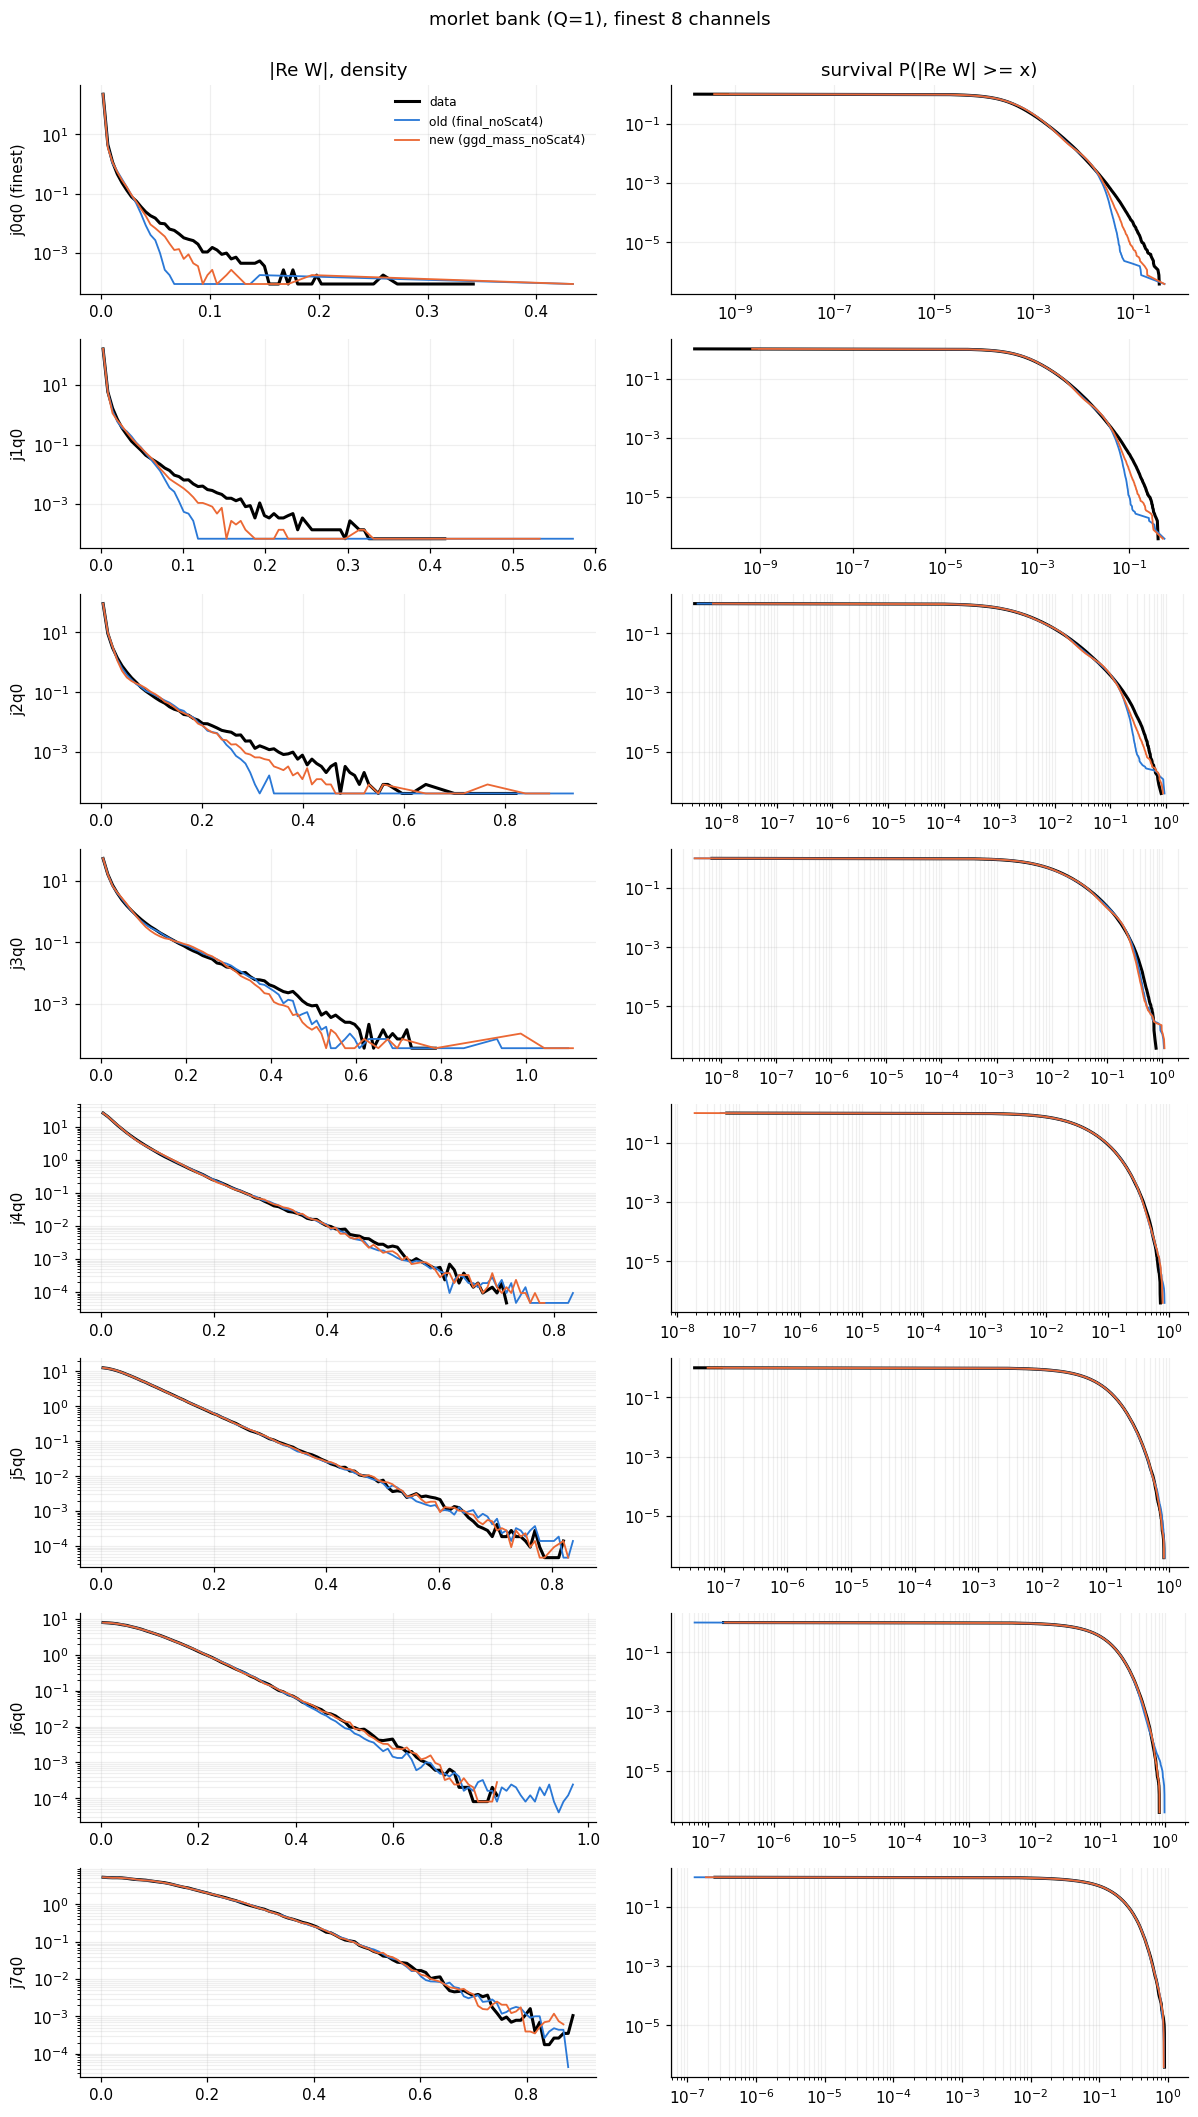

In [4]:
plot_tail_hists(x1, xs, bank='morlet', n_ch=8, n_series=N)

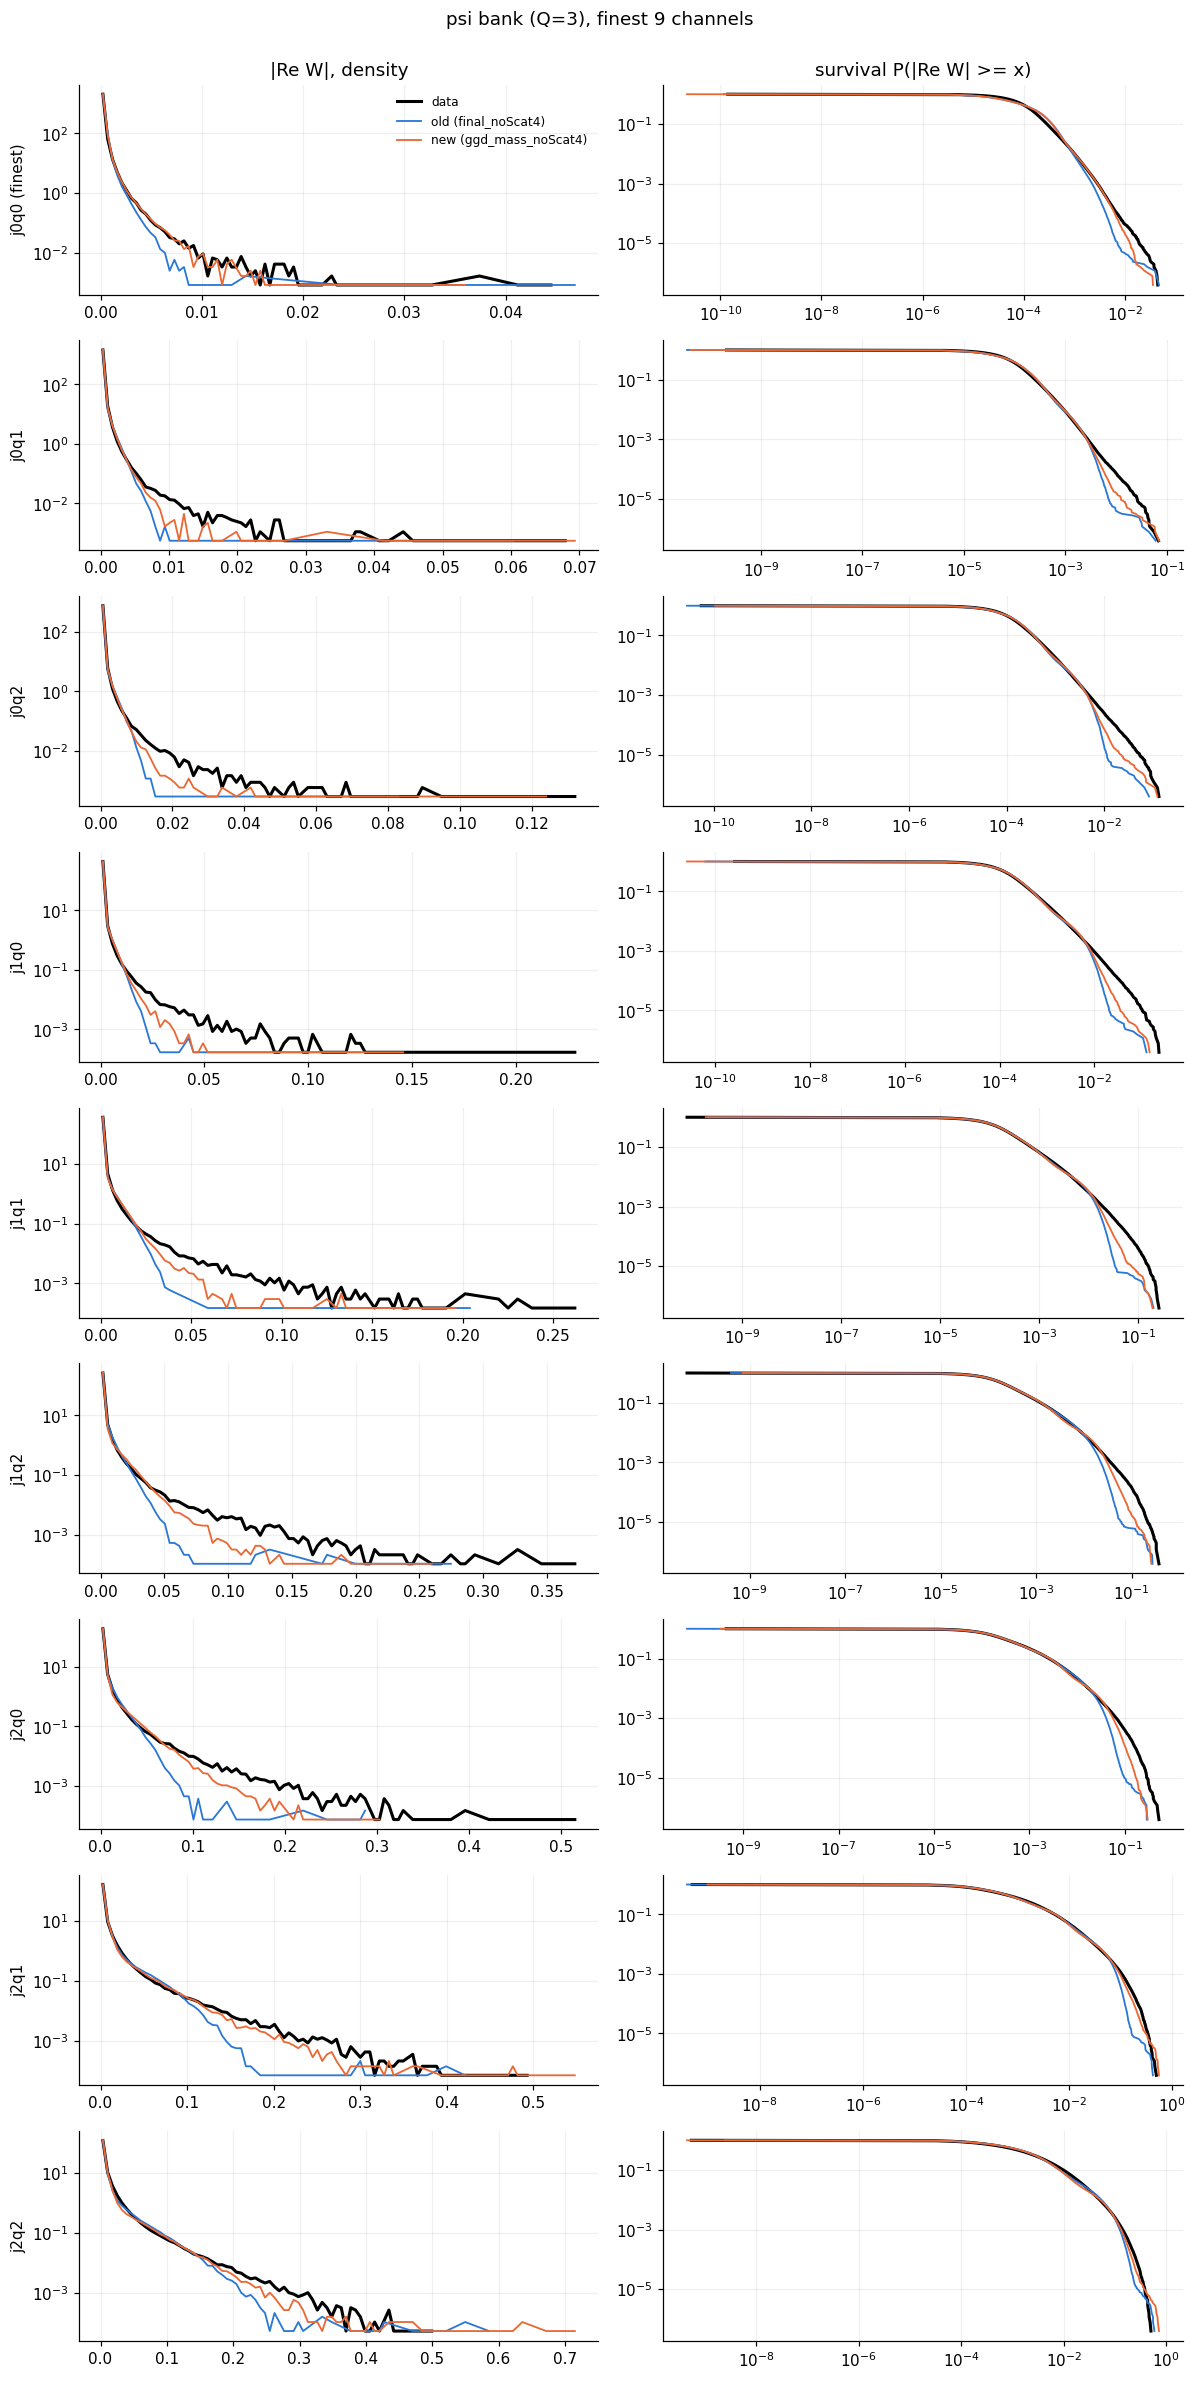

In [5]:
plot_tail_hists(x1, xs, bank='psi', n_ch=9, n_series=N)

## Statistics
Physical statistics, then the imposed moments at the end of the run (the two runs have different potential sets, so only the error distributions are comparable).

In [6]:
S_ref = compute_stats(x1)
S_runs = {k: compute_stats(v) for k, v in xs.items()}
ks = wavelet_ks(S_ref, S_runs)
summary_table(S_ref, S_runs, runs, THRESHOLD, ks=ks)

,reg,sched,n_terms,nt,n1,runtime_h,mm_final_median,mm_final_p90,mm_final_max,mm_n_above_1pct,S2_ratio_tau1,flat4_ratio_tau1,flat6_ratio_tau1,skew_tau1 (data 0.018),spec_logrms,spec_logrms_oct,wav_E_logrms,wav_flat_logrms,marg_KS,wav_KS_max
old (final_noScat4),0.00,2.00,4.00,55000.00,10000.00,3.70,0.00,0.00,0.25,10.00,0.93,0.72,2.17,-0.20,0.59,0.46,0.45,0.74,0.02,0.08
new (ggd_mass_noScat4),0.00,2.00,3.00,55000.00,10000.00,4.20,0.00,0.00,0.25,10.00,0.93,0.86,2.99,0.08,0.42,0.32,0.31,0.60,0.02,0.09


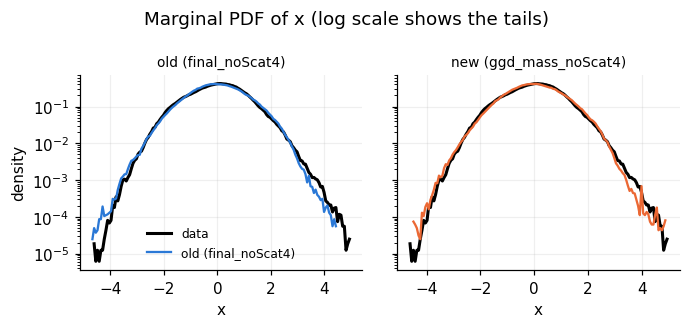

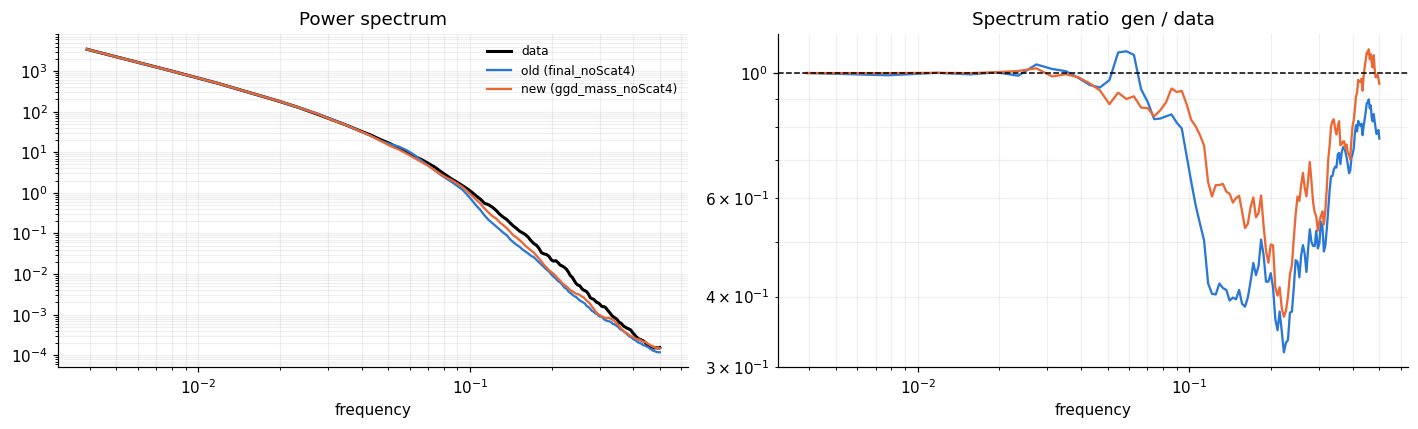

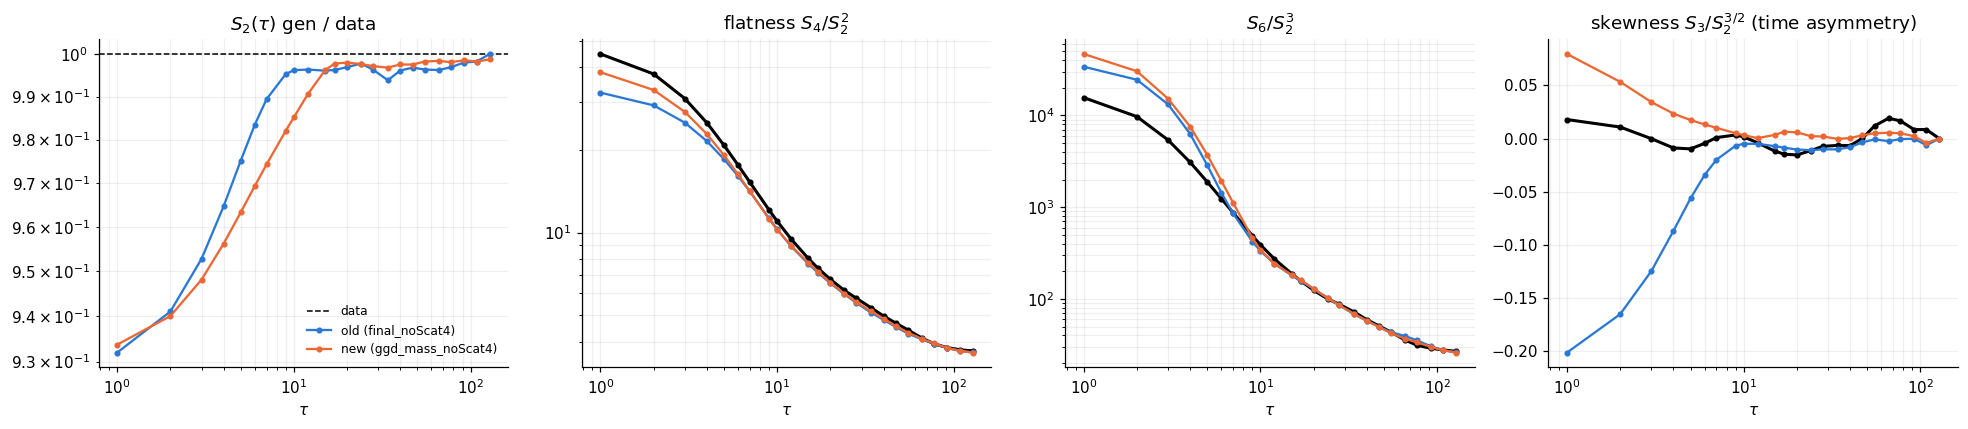

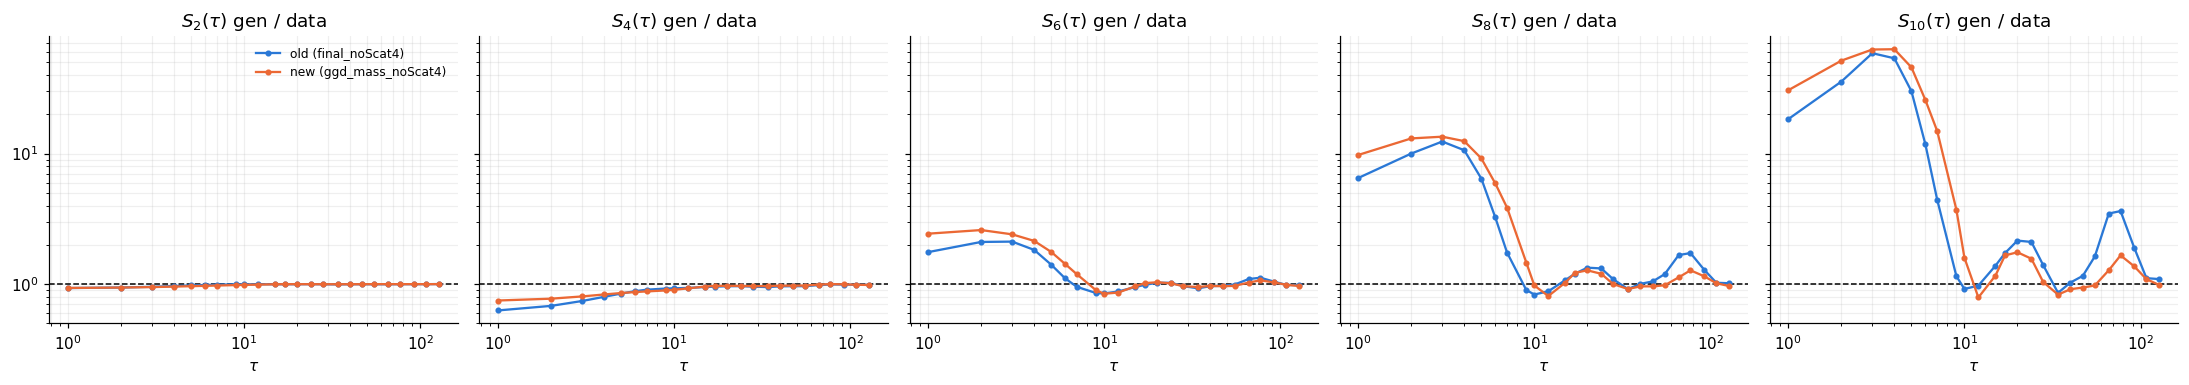

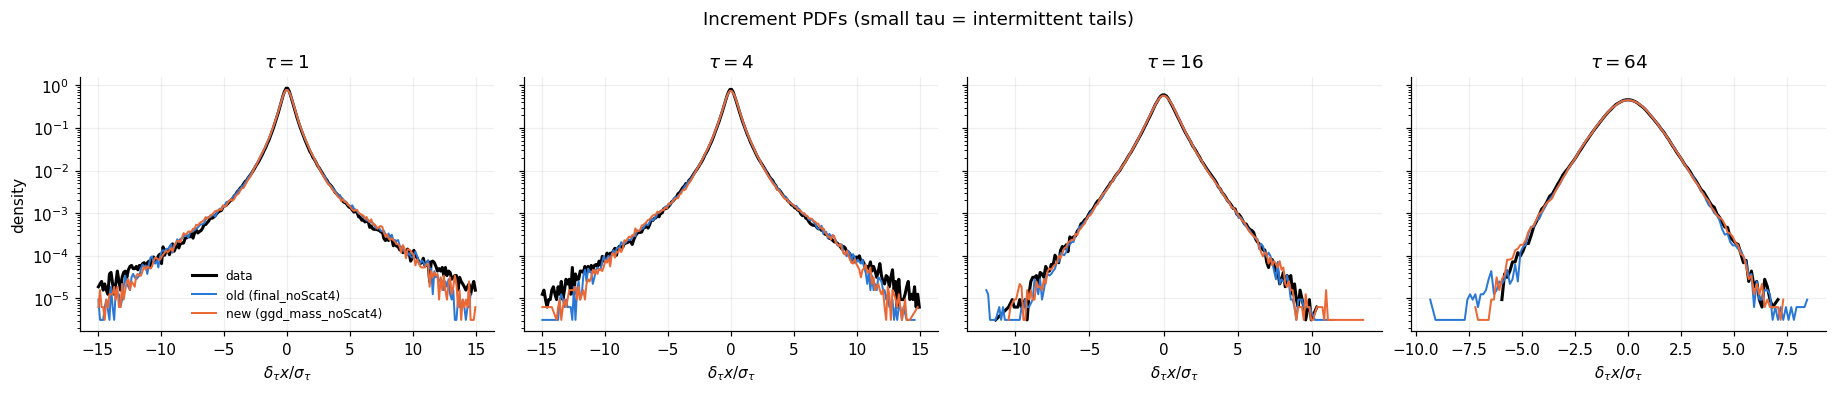

In [7]:
plot_marginals(S_ref, S_runs); plot_spectra(S_ref, S_runs); plot_structure(S_ref, S_runs); plot_structure_orders(S_ref, S_runs); plot_increment_pdfs(S_ref, S_runs)

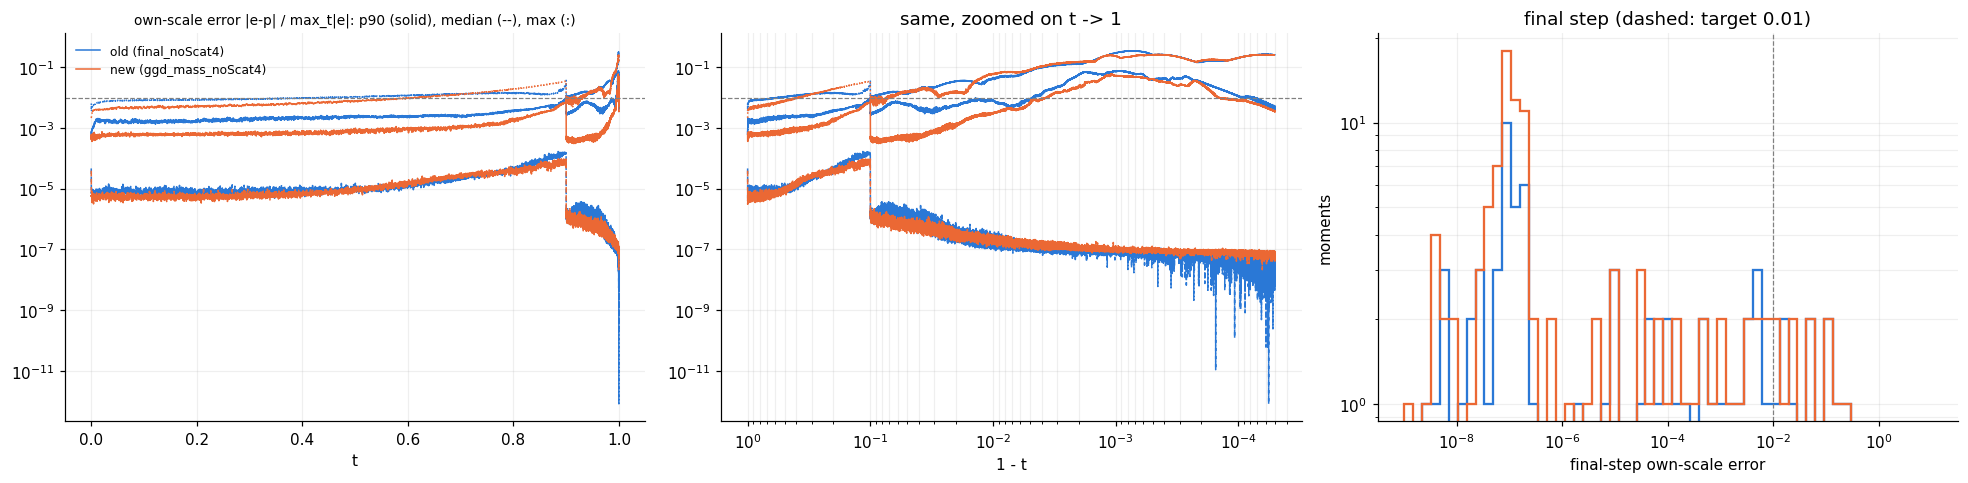

In [8]:
plot_moment_matching(runs, THRESHOLD)